# Importamos las librerías que necesitamos

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import scipy.stats as stats

import statsmodels.api as sm
from statsmodels.stats.outliers_influence import variance_inflation_factor
from statsmodels.stats.diagnostic import het_breuschpagan
from statsmodels.stats.stattools import durbin_watson

from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error

sns.set_theme(style='whitegrid')

## Cargamos los datos del kaggle


In [ ]:
df_raw = pd.read_csv('cards.csv')
print('Filas y columnas:', df_raw.shape)
df_raw.head()

Filas y columnas: (14642, 29)


,id,name,type,desc,atk,def,level,race,attribute,scale,...,views,viewsweek,upvotes,downvotes,formats,treated_as,tcg_date,ocg_date,konami_id,has_effect
0,80181649,"""A Case for K9""",Spell Card,"When this card is activated: You can add 1 ""K9...",NaN,NaN,NaN,Continuous,NaN,NaN,...,440159,5461,0,0,TCG|OCG|Master Duel,NaN,2025-07-31,2025-03-22,21385.0,1
1,34541863,"""A"" Cell Breeding Device",Spell Card,"During each of your Standby Phases, put 1 A-Co...",NaN,NaN,NaN,Continuous,NaN,NaN,...,353494,400,118,110,Duel Links|Common Charity|Edison|TCG|OCG|Maste...,NaN,2007-05-16,2007-02-15,7128.0,1
2,64163367,"""A"" Cell Incubator",Spell Card,Each time an A-Counter(s) is removed from play...,NaN,NaN,NaN,Continuous,NaN,NaN,...,245965,336,25,20,Duel Links|Common Charity|Edison|TCG|OCG|Maste...,NaN,2007-11-14,2007-07-21,7315.0,1
3,91231901,"""A"" Cell Recombination Device",Spell Card,Target 1 face-up monster on the field; send 1 ...,NaN,NaN,NaN,Quick-Play,NaN,NaN,...,251675,273,19,15,Duel Links|Common Charity|TCG|OCG|Master Duel,NaN,2016-11-03,2016-07-09,12653.0,1
4,73262676,"""A"" Cell Scatter Burst",Spell Card,"Select 1 face-up ""Alien"" monster you control. ...",NaN,NaN,NaN,Quick-Play,NaN,NaN,...,198306,357,12,4,Duel Links|Common Charity|Edison|TCG|OCG|Maste...,NaN,2007-02-28,2006-11-16,6994.0,1


In [ ]:

print(df_raw['type'].value_counts())
print()
print('Nulos:')
print(df_raw[['atk', 'def', 'level', 'attribute']].isnull().sum())
print()
print('Cartas repetidas:', df_raw['id'].duplicated().sum())

type
Effect Monster                     5150
Spell Card                         2905
Trap Card                          2094
Normal Monster                      672
XYZ Monster                         596
Fusion Monster                      571
Tuner Monster                       517
Link Monster                        481
Synchro Monster                     476
Pendulum Effect Monster             287
Flip Effect Monster                 194
Ritual Effect Monster               139
Skill Card                          124
Token                               106
Synchro Tuner Monster                59
Gemini Monster                       45
Union Effect Monster                 39
Spirit Monster                       38
Pendulum Normal Monster              36
Toon Monster                         18
Pendulum Effect Fusion Monster       15
Ritual Monster                       15
Normal Tuner Monster                 14
Pendulum Tuner Effect Monster        14
Pendulum Flip Effect Monster       

In [ ]:
def grupo_carta(t):
    if 'Link' in t:
        return 'Monstruo Link'
    if 'Monster' in t:
        return 'Monstruo (resto)'
    return t

df_raw['grupo'] = df_raw['type'].apply(grupo_carta)
df_raw.groupby('grupo')[['atk', 'def', 'level', 'attribute']].apply(lambda g: g.isnull().sum())

,atk,def,level,attribute
grupo,,,,
Monstruo (resto),1,1,1,1
Monstruo Link,0,481,373,0
Skill Card,124,124,124,124
Spell Card,2905,2905,2905,2905
Token,106,106,106,106
Trap Card,2094,2094,2094,2094


##  Limpieza de los datos


In [ ]:
print('Filas originales:', len(df_raw))


df0 = df_raw.drop_duplicates(subset='id').copy()
print('1. Sin repetidas:', len(df0))


mon = df0[df0['type'].str.contains('Monster', na=False)].copy()
print('2. Solo monstruos:', len(mon))


mon = mon[~mon['type'].str.contains('Link', na=False)]
print('3. Sin monstruos Link:', len(mon))

print()
print('Valores indefinidos que quedan antes de borrar:')
print(mon[['atk', 'def', 'level', 'attribute', 'views', 'upvotes']].isnull().sum())

mon = mon.dropna(subset=['atk', 'def', 'level', 'attribute', 'views', 'upvotes'])
print()
print(' valores indefinidos:', len(mon))

mon = mon[(mon['atk'] >= 0) & (mon['def'] >= 0)]
print('5. Sin valores:', len(mon))

Filas originales: 14642
1. Sin repetidas: 14642
2. Solo monstruos: 9413
3. Sin monstruos Link: 8932

Valores indefinidos que quedan antes de borrar:
atk          1
def          1
level        1
attribute    1
views        0
upvotes      0
dtype: int64

 valores indefinidos: 8931
5. Sin valores: 8847


In [ ]:

def agrupar_tipo(t):
    for clave in ['Normal', 'XYZ', 'Fusion', 'Synchro', 'Ritual', 'Pendulum', 'Tuner']:
        if clave in t:
            return clave
    return 'Effect'

mon['tipo_grupo'] = mon['type'].apply(agrupar_tipo)

mon['views_log'] = np.log1p(mon['views'])
mon['upvotes_log'] = np.log1p(mon['upvotes'])

mon['tipo_grupo'].value_counts()

,count
tipo_grupo,
Effect,5429
Normal,722
XYZ,594
Fusion,576
Synchro,538
Tuner,518
Pendulum,310
Ritual,160


In [ ]:
df = mon[['atk', 'def', 'level', 'views_log', 'upvotes_log', 'attribute', 'tipo_grupo']].copy()
df = df.rename(columns={'def': 'defensa'})

df = pd.get_dummies(df, columns=['attribute', 'tipo_grupo'], drop_first=True, dtype=float)

print('Datos listos:', df.shape)

print('valores indefinidos que quedan en total:', df.isnull().sum().sum())
assert df.isnull().sum().sum() == 0, 'Todavía hay valores indefinidos'
df.head()

Datos listos: (8847, 18)
valores indefinidos que quedan en total: 0


,atk,defensa,level,views_log,upvotes_log,attribute_DIVINE,attribute_EARTH,attribute_FIRE,attribute_LIGHT,attribute_WATER,attribute_WIND,tipo_grupo_Fusion,tipo_grupo_Normal,tipo_grupo_Pendulum,tipo_grupo_Ritual,tipo_grupo_Synchro,tipo_grupo_Tuner,tipo_grupo_XYZ
11,500.0,1500.0,3.0,12.354156,3.178054,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
12,1250.0,2100.0,5.0,12.027197,3.526361,0.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0
13,800.0,1200.0,3.0,13.245497,2.995732,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
15,1800.0,800.0,4.0,13.181162,3.295837,0.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0
17,300.0,200.0,2.0,12.212422,2.564949,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


## Análisis exploratorio

In [ ]:
df.describe()

,atk,defensa,level,views_log,upvotes_log,attribute_DIVINE,attribute_EARTH,attribute_FIRE,attribute_LIGHT,attribute_WATER,attribute_WIND,tipo_grupo_Fusion,tipo_grupo_Normal,tipo_grupo_Pendulum,tipo_grupo_Ritual,tipo_grupo_Synchro,tipo_grupo_Tuner,tipo_grupo_XYZ
count,8847.000000,8847.000000,8847.000000,8847.000000,8847.000000,8847.000000,8847.000000,8847.000000,8847.000000,8847.000000,8847.000000,8847.000000,8847.000000,8847.000000,8847.000000,8847.000000,8847.000000,8847.000000
mean,1524.403753,1298.576919,4.708037,11.413178,1.390426,0.000226,0.225387,0.088279,0.207641,0.103651,0.094721,0.065107,0.081610,0.035040,0.018085,0.060812,0.058551,0.067141
std,960.465318,879.378209,2.441327,1.154896,0.998314,0.015035,0.417861,0.283716,0.405641,0.304824,0.292846,0.246728,0.273784,0.183892,0.133267,0.238998,0.234796,0.250281
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,800.000000,600.000000,3.000000,10.633943,0.693147,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
50%,1500.000000,1200.000000,4.000000,11.361568,1.386294,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
75%,2200.000000,2000.000000,6.000000,12.174597,1.945910,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
max,5000.000000,5000.000000,13.000000,17.072157,7.866722,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000


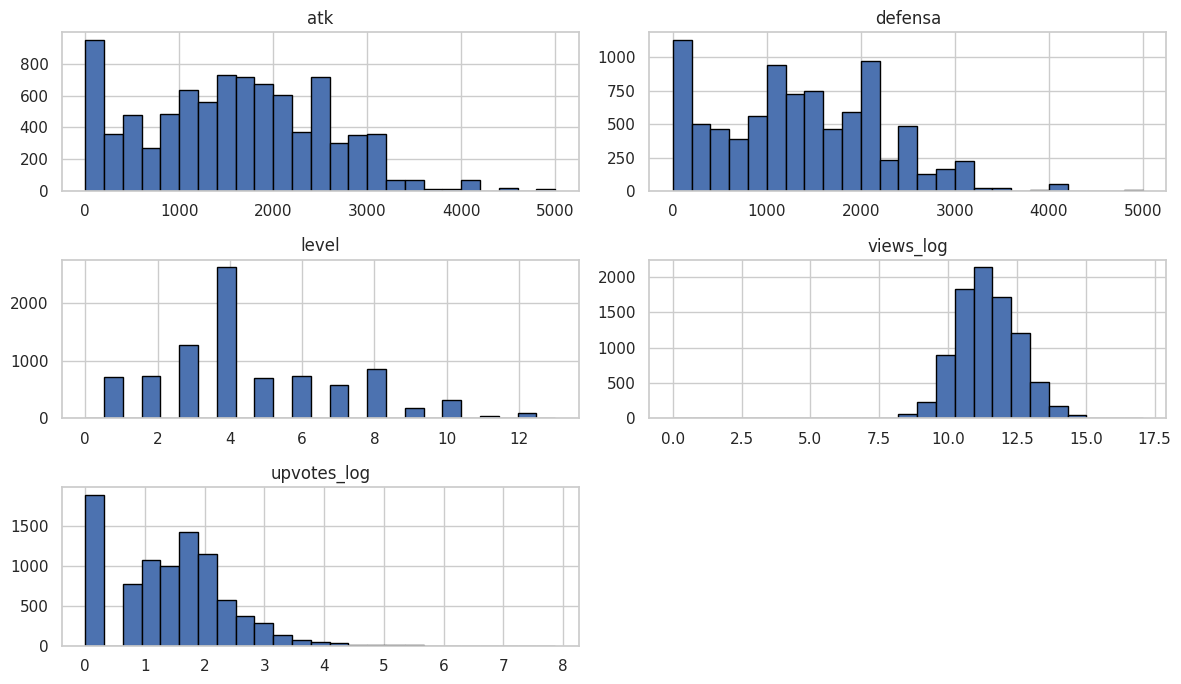

In [ ]:

numericas = ['atk', 'defensa', 'level', 'views_log', 'upvotes_log']
df[numericas].hist(figsize=(12, 7), bins=25, edgecolor='black')
plt.tight_layout()
plt.show()

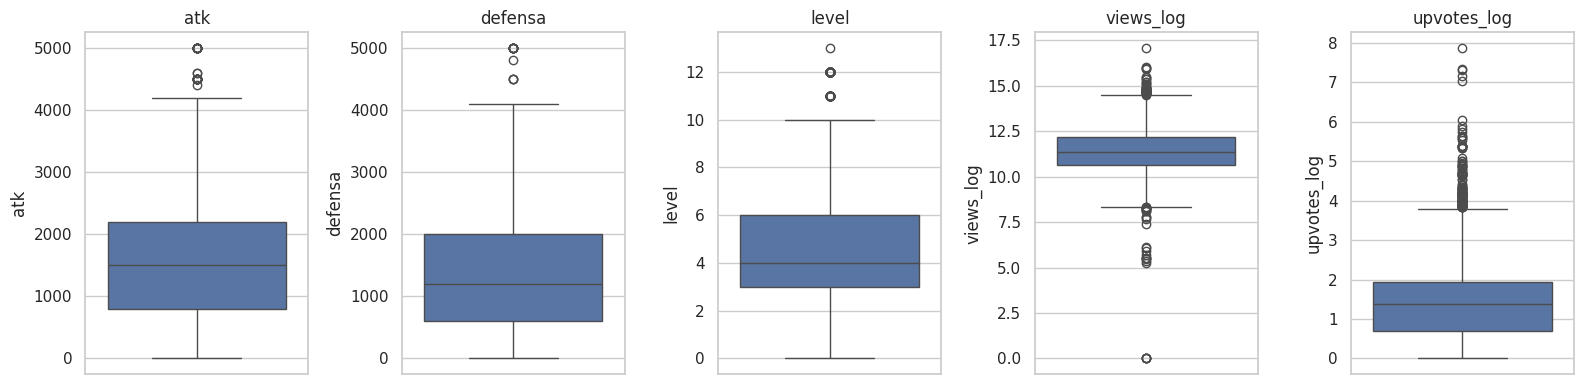

In [ ]:

fig, axes = plt.subplots(1, 5, figsize=(16, 4))
for ax, col in zip(axes, numericas):
    sns.boxplot(y=df[col], ax=ax)
    ax.set_title(col)
plt.tight_layout()
plt.show()

## Correlación de Pearson

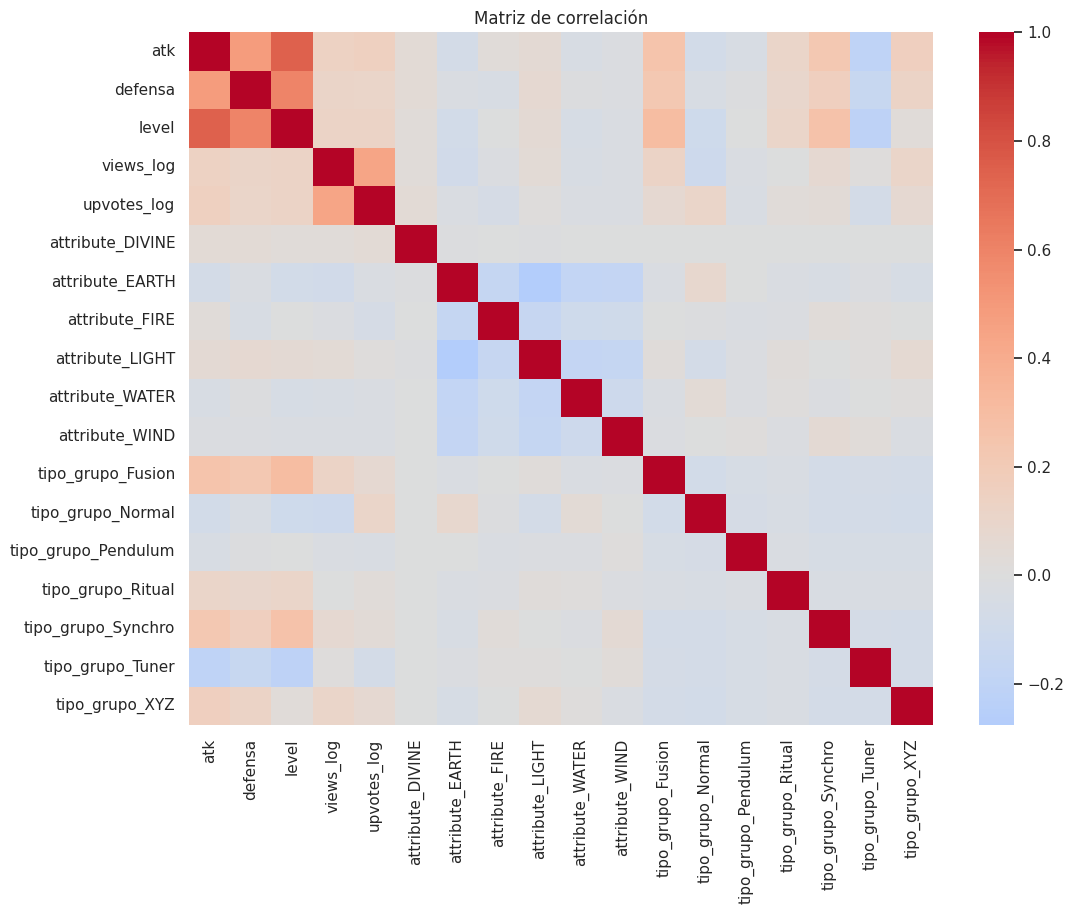

In [ ]:
corr = df.corr(method='pearson')

plt.figure(figsize=(12, 9))
sns.heatmap(corr, cmap='coolwarm', center=0)
plt.title('Matriz de correlación')
plt.show()

In [ ]:

corr_atk = corr['atk'].drop('atk').sort_values(key=abs, ascending=False)
corr_atk

,atk
level,0.750550
defensa,0.484248
tipo_grupo_Fusion,0.252746
tipo_grupo_Synchro,0.218296
tipo_grupo_Tuner,-0.204543
tipo_grupo_XYZ,0.162296
upvotes_log,0.153394
views_log,0.141287
tipo_grupo_Ritual,0.104211
tipo_grupo_Normal,-0.080266


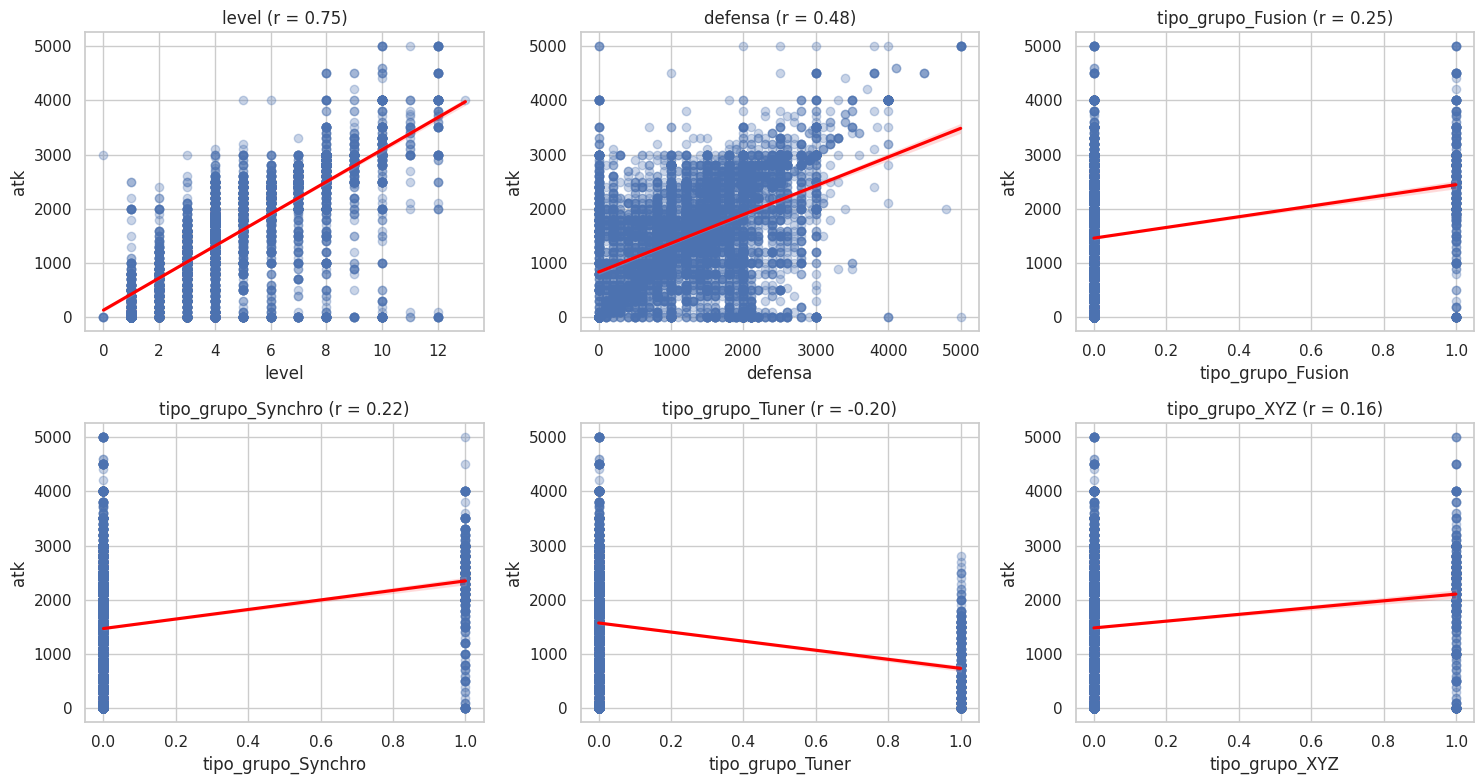

In [ ]:

top6 = corr_atk.head(6).index

fig, axes = plt.subplots(2, 3, figsize=(15, 8))
for ax, col in zip(axes.ravel(), top6):
    sns.regplot(x=df[col], y=df['atk'], ax=ax, scatter_kws={'alpha': 0.3}, line_kws={'color': 'red'})
    ax.set_title(f'{col} (r = {corr_atk[col]:.2f})')
plt.tight_layout()
plt.show()

##  Separar entrenamiento y prueba


In [ ]:
X = df.drop(columns=['atk'])
y = df['atk']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

print('Entrenamiento:', X_train.shape)
print('Prueba:', X_test.shape)

Entrenamiento: (7077, 17)
Prueba: (1770, 17)


## Modelo de regresión lineal múltiple

In [ ]:
X_train_c = sm.add_constant(X_train)
X_test_c = sm.add_constant(X_test, has_constant='add')

modelo1 = sm.OLS(y_train, X_train_c).fit()
print(modelo1.summary())

                            OLS Regression Results                            
Dep. Variable:                    atk   R-squared:                       0.598
Model:                            OLS   Adj. R-squared:                  0.598
Method:                 Least Squares   F-statistic:                     619.0
Date:                Thu, 29 Oct 2026   Prob (F-statistic):               0.00
Time:                        23:28:51   Log-Likelihood:                -55400.
No. Observations:                7077   AIC:                         1.108e+05
Df Residuals:                    7059   BIC:                         1.110e+05
Df Model:                          17                                         
Covariance Type:            nonrobust                                         
                          coef    std err          t      P>|t|      [0.025      0.975]
---------------------------------------------------------------------------------------
const                 -74.0603    

In [ ]:
pred_train = modelo1.predict(X_train_c)
pred_test = modelo1.predict(X_test_c)

r2_train = r2_score(y_train, pred_train)
r2_test = r2_score(y_test, pred_test)
rmse_train = np.sqrt(mean_squared_error(y_train, pred_train))
rmse_test = np.sqrt(mean_squared_error(y_test, pred_test))

print(f'R2 entrenamiento: {r2_train:.3f}')
print(f'R2 prueba:        {r2_test:.3f}')
print(f'RMSE entrenamiento: {rmse_train:.1f}')
print(f'RMSE prueba:        {rmse_test:.1f}')
print(f'R2 ajustado:        {modelo1.rsquared_adj:.3f}')

R2 entrenamiento: 0.598
R2 prueba:        0.572
RMSE entrenamiento: 607.4
RMSE prueba:        632.6
R2 ajustado:        0.598


In [ ]:

mae_test = mean_absolute_error(y_test, pred_test)
print(f'MAE prueba: {mae_test:.1f}')


print(f'Estadistico F = {modelo1.fvalue:.1f}  |  p-valor = {modelo1.f_pvalue:.4g}')

MAE prueba: 455.0
Estadistico F = 619.0  |  p-valor = 0


In [ ]:

cv_r2 = cross_val_score(LinearRegression(), X, y, cv=5, scoring='r2')
print('R2 de cada parte:', np.round(cv_r2, 3))
print(f'R2 promedio = {cv_r2.mean():.3f} (desviación {cv_r2.std():.3f})')

R2 de cada parte: [0.635 0.519 0.609 0.587 0.587]
R2 promedio = 0.587 (desviación 0.039)


##  Revisar los supuestos del modelo


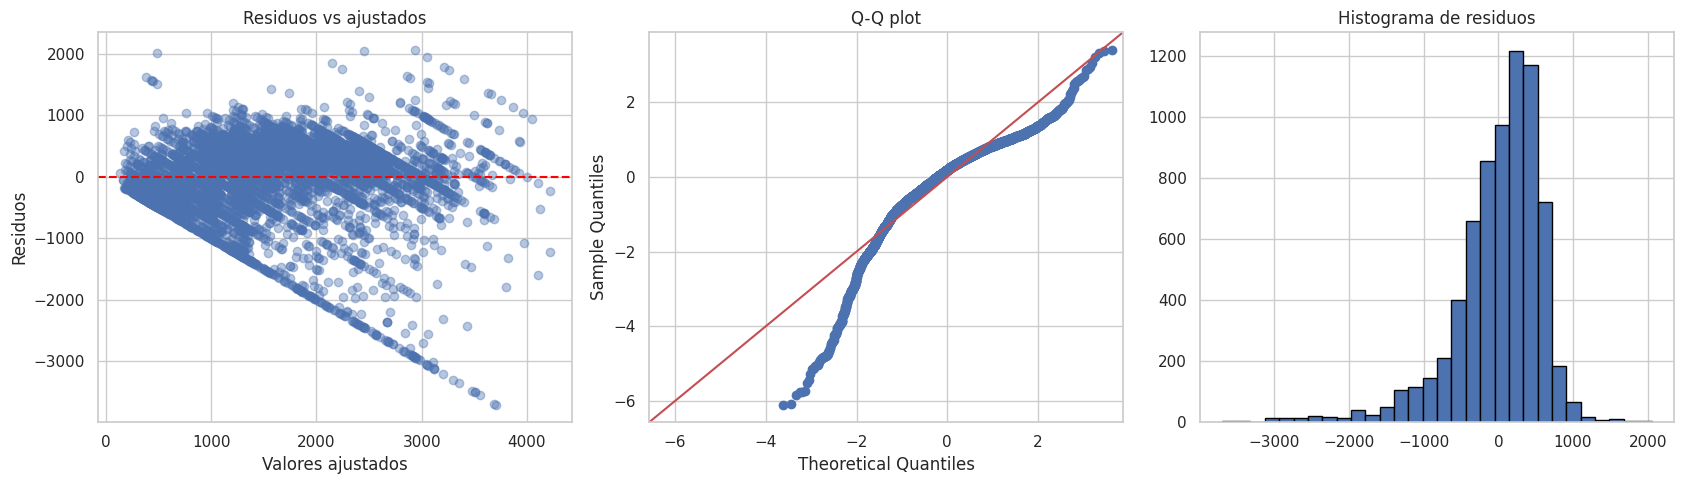

In [ ]:
residuos = modelo1.resid
ajustados = modelo1.fittedvalues

fig, axes = plt.subplots(1, 3, figsize=(17, 5))


axes[0].scatter(ajustados, residuos, alpha=0.4)
axes[0].axhline(0, color='red', linestyle='--')
axes[0].set_xlabel('Valores ajustados')
axes[0].set_ylabel('Residuos')
axes[0].set_title('Residuos vs ajustados')


sm.qqplot(residuos, line='45', fit=True, ax=axes[1])
axes[1].set_title('Q-Q plot')


axes[2].hist(residuos, bins=30, edgecolor='black')
axes[2].set_title('Histograma de residuos')

plt.tight_layout()
plt.show()

In [ ]:

muestra = residuos.sample(min(len(residuos), 5000), random_state=42)
stat, p = stats.shapiro(muestra)
print(f'Shapiro-Wilk: p = {p:.4g}')
if p > 0.05:
    print('Los residuos parecen normales')
else:
    print('Los residuos NO son normales')

Shapiro-Wilk: p = 8.216e-50
Los residuos NO son normales


In [ ]:

bp_stat, bp_p, _, _ = het_breuschpagan(residuos, X_train_c)
print(f'Breusch-Pagan: p = {bp_p:.4g}')
if bp_p > 0.05:
    print('La varianza de los residuos es constante')
else:
    print('La varianza de los residuos NO es constante')


dw = durbin_watson(residuos)
print(f'Durbin-Watson = {dw:.3f}')

Breusch-Pagan: p = 2.349e-156
La varianza de los residuos NO es constante
Durbin-Watson = 1.975


In [ ]:

vif = pd.DataFrame()
vif['Variable'] = X_train_c.columns
vif['VIF'] = [variance_inflation_factor(X_train_c.values, i) for i in range(X_train_c.shape[1])]
vif = vif[vif['Variable'] != 'const'].sort_values('VIF', ascending=False)
vif

,Variable,VIF
2,level,1.843252
1,defensa,1.640577
6,attribute_EARTH,1.429590
8,attribute_LIGHT,1.390631
3,views_log,1.315504
4,upvotes_log,1.294601
9,attribute_WATER,1.240098
10,attribute_WIND,1.225708
7,attribute_FIRE,1.209066
11,tipo_grupo_Fusion,1.181045


## Segundo modelo: quitar las variables que no sirven


In [ ]:
pvalores = modelo1.pvalues.drop('const')
variables_buenas = pvalores[pvalores < 0.05].index.tolist()

print('Variables que nos quedamos:', variables_buenas)
print('Variables que quitamos:', [v for v in pvalores.index if v not in variables_buenas])

Variables que nos quedamos: ['defensa', 'level', 'upvotes_log', 'attribute_FIRE', 'attribute_WIND', 'tipo_grupo_Fusion', 'tipo_grupo_Pendulum', 'tipo_grupo_Ritual', 'tipo_grupo_Synchro', 'tipo_grupo_Tuner', 'tipo_grupo_XYZ']
Variables que quitamos: ['views_log', 'attribute_DIVINE', 'attribute_EARTH', 'attribute_LIGHT', 'attribute_WATER', 'tipo_grupo_Normal']


In [ ]:
X_train2 = sm.add_constant(X_train[variables_buenas])
X_test2 = sm.add_constant(X_test[variables_buenas], has_constant='add')

modelo2 = sm.OLS(y_train, X_train2).fit()
print(modelo2.summary())

                            OLS Regression Results                            
Dep. Variable:                    atk   R-squared:                       0.598
Model:                            OLS   Adj. R-squared:                  0.597
Method:                 Least Squares   F-statistic:                     955.1
Date:                Thu, 29 Oct 2026   Prob (F-statistic):               0.00
Time:                        23:28:52   Log-Likelihood:                -55405.
No. Observations:                7077   AIC:                         1.108e+05
Df Residuals:                    7065   BIC:                         1.109e+05
Df Model:                          11                                         
Covariance Type:            nonrobust                                         
                          coef    std err          t      P>|t|      [0.025      0.975]
---------------------------------------------------------------------------------------
const                  63.6530    

In [ ]:

pred_test2 = modelo2.predict(X_test2)

comparacion = pd.DataFrame({
    'Modelo': ['Completo', 'Reducido'],
    'Nº variables': [X_train.shape[1], len(variables_buenas)],
    'R2 ajustado': [modelo1.rsquared_adj, modelo2.rsquared_adj],
    'R2 prueba': [r2_test, r2_score(y_test, pred_test2)],
    'RMSE prueba': [rmse_test, np.sqrt(mean_squared_error(y_test, pred_test2))],
    'AIC': [modelo1.aic, modelo2.aic],
    'BIC': [modelo1.bic, modelo2.bic],
})
comparacion

,Modelo,Nº variables,R2 ajustado,R2 prueba,RMSE prueba,AIC,BIC
0,Completo,17,0.597527,0.572412,632.644544,110835.849921,110959.412818
1,Reducido,11,0.597300,0.572235,632.775467,110833.847762,110916.223026


In [ ]:

f_stat, f_p, gl = modelo1.compare_f_test(modelo2)
print(f'F = {f_stat:.3f} | p-valor = {f_p:.4f} | variables quitadas = {gl:.0f}')

F = 1.663 | p-valor = 0.1257 | variables quitadas = 6


##  Predicciones vs. valores reales

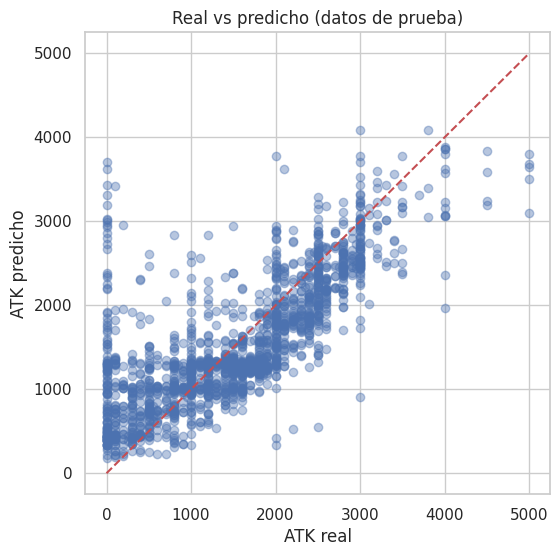

In [ ]:
plt.figure(figsize=(6, 6))
plt.scatter(y_test, pred_test2, alpha=0.4)
limite = [0, max(y_test.max(), pred_test2.max())]
plt.plot(limite, limite, 'r--')
plt.xlabel('ATK real')
plt.ylabel('ATK predicho')
plt.title('Real vs predicho (datos de prueba)')
plt.show()